# Financial Analysis and Validation
FRE-GY 6931 · Team 3 · AMM with Trading Simulation and Liquidity Risk Analytics

This notebook follows Section 3 of the proposal. Every section states its assumptions before its results.
The swap math lives in `amm_model.py` and uses the same integer rules as the Solidity pool, so model values
can be reconciled with Sepolia transactions.

| # | Analysis task | Status |
|---|---|---|
| 1 | Price impact and depth | done |
| 2 | Impermanent loss | done, matches the closed form |
| 3 | LP profitability | done |
| 4 | Fixed versus dynamic fees | done |
| 5 | Trader paper trading and backtest | done, on Kraken ETH/USD hourly data |
| 6 | Protocol revenue and break-even | done |
| 7 | Oracle and on-chain reconciliation | contracts deployed on Sepolia; model reconciled with the contract's unit-test vectors; on-chain swap pending liquidity |

Fee-accounting rules in `amm_model.py` (fee on input, 0.05% protocol share leaves the reserves, LP share stays, √(x·y) first
mint, proportional shares after) were checked against `packages/hardhat/contracts/AMMPool.sol` on main (commit 89b3ae0) and
match digit for digit on the contract's own test vectors (Section 7a). The dynamic-fee rule in Section 4 is the contract's.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

import amm_model as amm

# Chart style: categorical slots 1-3 of the reference palette (validated for 3 series),
# recessive axes and grid, text in ink colors rather than series colors.
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": INK_2, "ytick.color": INK_2, "font.size": 10.5,
    "lines.linewidth": 2, "legend.frameon": False,
})
pct = FuncFormatter(lambda v, _: f"{v:.0%}" if v >= 0.01 else f"{v:.1%}")
usd = FuncFormatter(lambda v, _: f"-${abs(v):,.0f}" if v < 0 else f"${v:,.0f}")

## 1. Price impact and depth

**Question.** How much does a trader lose to the fee and to the curve, as the trade grows and as the pool gets deeper?

**Assumptions**
- Pair WETH/USDX. Reference price 1 WETH = 2,500 USDX, and 1 USDX = 1 USD (USDX is an unbacked test token).
- The pool starts balanced at that price. Depth is total value locked (TVL), split half and half.
- Three depths: \$20k (a new pool seeded by the team), \$100k and \$500k.
- The trader buys WETH with USDX. Trades from \$100 to \$50,000.
- Fee is the base tier, 0.30% of the input. Gas is excluded here and added in Section 3.

**Definitions** (all as a share of the trade's value at the pre-trade spot price)
- *Curve impact*: the cost of the same trade with no fee. For x·y = k it equals a / (x + a), where x is the USDX reserve and a is the trade.
- *Fee cost*: the extra cost the fee adds.
- *Total cost*: 1 − (WETH received × spot price) / USDX paid.

In [2]:
ETH_PRICE = 2_500.0
DEPTHS_TVL = [20_000, 100_000, 500_000]
trade_sizes = np.geomspace(100, 50_000, 80)

rows = []
for tvl in DEPTHS_TVL:
    usdx_reserve = tvl / 2
    weth_reserve = usdx_reserve / ETH_PRICE
    for a in trade_sizes:
        c = amm.execution_costs(a, usdx_reserve, weth_reserve, amm.BASE_FEE_BPS)
        rows.append({"tvl": tvl, "trade_usd": a, "trade_share_of_reserve": a / usdx_reserve, **c})
impact = pd.DataFrame(rows)

# Check the model against the closed form a / (x + a)
closed_form = impact.trade_usd / (impact.tvl / 2 + impact.trade_usd)
assert np.allclose(impact.curve_impact, closed_form, atol=1e-12)
print("Curve impact matches a / (x + a) for all", len(impact), "trades")

Curve impact matches a / (x + a) for all 240 trades


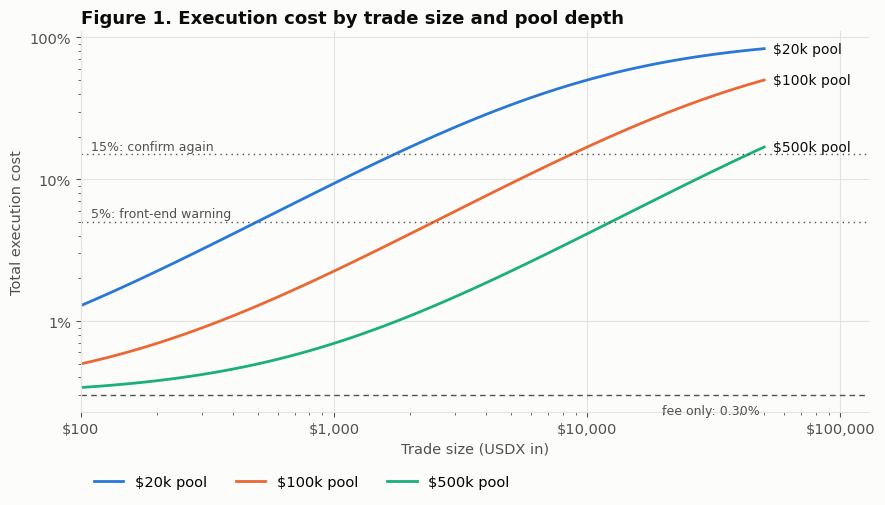

In [3]:
fig, ax = plt.subplots(figsize=(9, 5.2))
labels = {20_000: "$20k pool", 100_000: "$100k pool", 500_000: "$500k pool"}
for color, tvl in zip(SERIES, DEPTHS_TVL):
    d = impact[impact.tvl == tvl]
    ax.plot(d.trade_usd, d.total_cost, color=color, label=labels[tvl])
    last = d.iloc[-1]
    ax.annotate(labels[tvl], (last.trade_usd, last.total_cost), xytext=(6, 0),
                textcoords="offset points", va="center", color=INK, fontsize=10)

ax.axhline(0.003, color=INK_2, linestyle=(0, (4, 3)), linewidth=1)
ax.text(48_000, 0.0026, "fee only: 0.30%", color=INK_2, fontsize=9, ha="right", va="top")
for level, text in [(0.05, "5%: front-end warning"), (0.15, "15%: confirm again")]:
    ax.axhline(level, color=INK_2, linestyle=(0, (1, 3)), linewidth=1)
    ax.text(110, level * 1.08, text, color=INK_2, fontsize=9)

ax.set_xscale("log"); ax.set_yscale("log")
ax.xaxis.set_major_formatter(usd); ax.yaxis.set_major_formatter(pct)
ax.set_xlim(100, 50_000 * 2.6)
ax.set_xlabel("Trade size (USDX in)"); ax.set_ylabel("Total execution cost")
ax.set_title("Figure 1. Execution cost by trade size and pool depth")
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.13), ncol=3)
fig.tight_layout()
fig.savefig("figures/fig1_price_impact_by_depth.png", dpi=200)
plt.show()

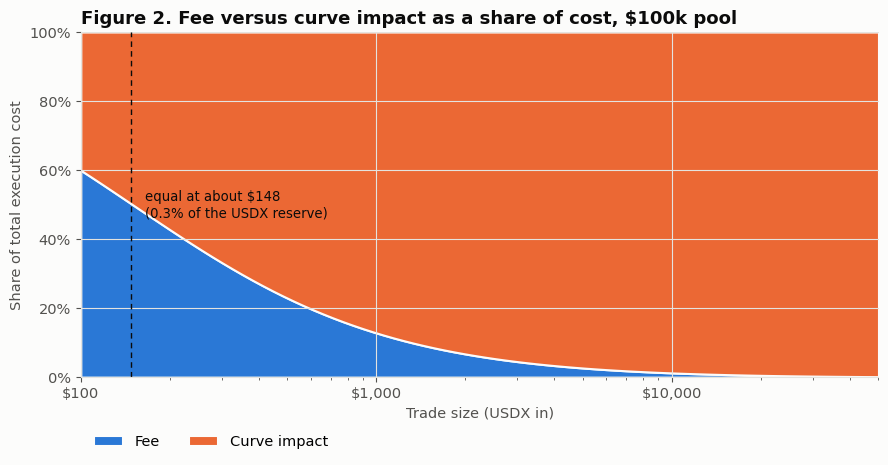

In [4]:
tvl = 100_000
d = impact[impact.tvl == tvl]
fig, ax = plt.subplots(figsize=(9, 4.8))
fee_share = d.fee_cost / d.total_cost
ax.stackplot(d.trade_usd, fee_share, 1 - fee_share, colors=SERIES[:2],
             labels=["Fee", "Curve impact"], edgecolor=SURFACE, linewidth=1.5)
cross = d.iloc[(fee_share - 0.5).abs().argmin()]
ax.axvline(cross.trade_usd, color=INK, linewidth=1, linestyle=(0, (4, 3)))
ax.annotate(f"equal at about ${cross.trade_usd:,.0f}\n({cross.trade_share_of_reserve:.1%} of the USDX reserve)",
            (cross.trade_usd, 0.5), xytext=(10, 0), textcoords="offset points", va="center", color=INK, fontsize=9.5)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(usd); ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlim(100, 50_000); ax.set_ylim(0, 1)
ax.set_xlabel("Trade size (USDX in)"); ax.set_ylabel("Share of total execution cost")
ax.set_title("Figure 2. Fee versus curve impact as a share of cost, $100k pool")
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.13), ncol=2)
fig.tight_layout()
fig.savefig("figures/fig2_cost_decomposition_100k.png", dpi=200)
plt.show()

**Table 1.** Cost of selected trades. The share column is the trade divided by the USDX reserve.

In [5]:
sizes = [1_000, 5_000, 10_000, 25_000]
table = []
for tvl in DEPTHS_TVL:
    x = tvl / 2
    for a in sizes:
        c = amm.execution_costs(a, x, x / ETH_PRICE)
        table.append({
            "Pool TVL": f"${tvl:,.0f}", "Trade": f"${a:,.0f}", "Share of reserve": f"{a / x:.1%}",
            "WETH received": round(c["amount_out"], 4), "Avg price": round(c["avg_price"], 1),
            "Fee cost": f"{c['fee_cost']:.2%}", "Curve impact": f"{c['curve_impact']:.2%}",
            "Total cost": f"{c['total_cost']:.2%}",
        })
pd.DataFrame(table)

,Pool TVL,Trade,Share of reserve,WETH received,Avg price,Fee cost,Curve impact,Total cost
0,"$20,000","$1,000",10.0%,0.3626,2757.5,0.25%,9.09%,9.34%
1,"$20,000","$5,000",50.0%,1.3307,3757.5,0.13%,33.33%,33.47%
2,"$20,000","$10,000",100.0%,1.9970,5007.5,0.08%,50.00%,50.08%
3,"$20,000","$25,000",250.0%,2.8547,8757.5,0.02%,71.43%,71.45%
4,"$100,000","$1,000",2.0%,0.3910,2557.5,0.29%,1.96%,2.25%
5,"$100,000","$5,000",10.0%,1.8132,2757.5,0.25%,9.09%,9.34%
6,"$100,000","$10,000",20.0%,3.3250,3007.5,0.21%,16.67%,16.88%
7,"$100,000","$25,000",50.0%,6.6533,3757.5,0.13%,33.33%,33.47%
8,"$500,000","$1,000",0.4%,0.3972,2517.5,0.30%,0.40%,0.70%
9,"$500,000","$5,000",2.0%,1.9550,2557.5,0.29%,1.96%,2.25%


**Table 2.** Largest trade that stays under each cost limit. Solving a / (x + a) = t for the curve part gives
a = x · t / (1 − t). The front end uses these limits for its price-impact warnings.

In [6]:
limits = [0.01, 0.05, 0.15]
max_rows = []
for tvl in DEPTHS_TVL:
    x = tvl / 2
    row = {"Pool TVL": f"${tvl:,.0f}"}
    for t in limits:
        row[f"curve impact <= {t:.0%}"] = f"${x * t / (1 - t):,.0f}"
    max_rows.append(row)
pd.DataFrame(max_rows)

,Pool TVL,curve impact <= 1%,curve impact <= 5%,curve impact <= 15%
0,"$20,000",$101,$526,"$1,765"
1,"$100,000",$505,"$2,632","$8,824"
2,"$500,000","$2,525","$13,158","$44,118"


**Findings**
- Fee and curve impact cost the same when the trade is about 0.3% of the USDX reserve. Smaller trades mostly pay the fee; larger trades mostly pay the curve.
- Curve impact depends only on the trade's share of the reserve. A trade five times larger needs a pool five times deeper to cost the same.
- For a newly seeded \$20k pool, a \$1,000 trade already loses about 9% to the curve. This is the strongest argument for attracting LP liquidity before inviting traders.
- These numbers set the front-end warnings: yellow above 5% total cost, red with a second confirmation above 15%.

**Limits.** The pool is assumed to start at the reference price, and no other trade lands between quote and execution (slippage is analyzed separately).

### 1b. Why x·y = k: constant sum and weighted pools compared

**Question.** The proposal uses the constant-product rule. Two alternatives are common: the *constant-sum* rule
x + P₀·y = k, which quotes a fixed price with no curve impact, and the *weighted* rule x^w·y^(1−w) = k (Balancer),
which lets the LP hold an unequal split such as 80% WETH / 20% USDX. How do the three compare for the trader and for the LP?

**Set-up.** All three pools hold \$100k at 1 WETH = 2,500 USDX. The 50/50 pools hold 50,000 USDX + 20 WETH; the 80/20 pool
holds 20,000 USDX + 32 WETH (80% of its value in WETH). Fee 0.30% on the input in every case.

| Rule | Invariant | Spot price (USDX per WETH) | Output for a USDX trade a |
|---|---|---|---|
| Constant sum | x + P₀·y = k | P₀, fixed | a / P₀, until y runs out |
| Constant product (50/50) | x·y = k | x / y | y·a / (x + a) |
| Weighted (w = USDX weight) | x^w·y^(1−w) = k | (x / w) / (y / (1−w)) | y·(1 − (x / (x + a))^(w/(1−w))) |

Fee-free LP value relative to holding, when the external price ends at r times the start (arbitrageurs do the rebalancing):
constant sum 2·min(1, r) / (1 + r); weighted r^(1−w) / ((1−w)·r + w); the 50/50 case w = 0.5 gives 2√r / (1 + r), the Section 2 formula.
All three curves are checked below by replaying the arbitrage trade on the reserves.

In [7]:
W_USDX = 0.20   # USDX weight in the 80/20 pool; WETH carries the other 80%

def weighted_amount_out(amount_in, reserve_in, reserve_out, w_in, w_out, fee_bps=amm.BASE_FEE_BPS):
    net = amount_in * (amm.BPS - fee_bps) / amm.BPS
    return reserve_out * (1 - (reserve_in / (reserve_in + net)) ** (w_in / w_out))

def constant_sum_amount_out(amount_in, reserve_out, price, fee_bps=amm.BASE_FEE_BPS):
    net = amount_in * (amm.BPS - fee_bps) / amm.BPS
    out = net / price
    return out if out <= reserve_out else np.nan   # the pool cannot fill more than it holds

def lp_vs_hold_constant_sum(r):
    return 2 * min(1.0, r) / (1 + r) - 1

def lp_vs_hold_weighted(r, w_usdx):
    w_weth = 1 - w_usdx
    return r ** w_weth / (w_weth * r + w_usdx) - 1

# Replay the fee-free arbitrage on the reserves to confirm the closed forms.
x0, y0 = 50_000.0, 20.0                            # 50/50 pools at $100k TVL
x8, y8 = 0.2 * (x0 + y0 * ETH_PRICE), 0.8 * (x0 + y0 * ETH_PRICE) / ETH_PRICE   # 80/20 pool
for r in [0.5, 0.75, 1.0, 1.5, 2.0]:
    p = r * ETH_PRICE
    hold50, hold80 = x0 + y0 * p, x8 + y8 * p
    # constant sum: the arbitrageur takes the whole cheaper side at the stale price
    cs_value = 2 * x0 if r > 1 else 2 * y0 * p if r < 1 else hold50
    assert abs(cs_value / hold50 - 1 - lp_vs_hold_constant_sum(r)) < 1e-12
    # weighted: with the invariant fixed, x ∝ p^(1-w) and y ∝ p^(-w) after the rebalance
    xw, yw = x8 * r ** (1 - W_USDX), y8 * r ** (-W_USDX)
    assert abs(xw ** W_USDX * yw ** (1 - W_USDX) - x8 ** W_USDX * y8 ** (1 - W_USDX)) < 1e-6
    assert abs((xw + yw * p) / hold80 - 1 - lp_vs_hold_weighted(r, W_USDX)) < 1e-12
print("Closed forms match the replayed arbitrage for constant-sum and 80/20 pools")

Closed forms match the replayed arbitrage for constant-sum and 80/20 pools


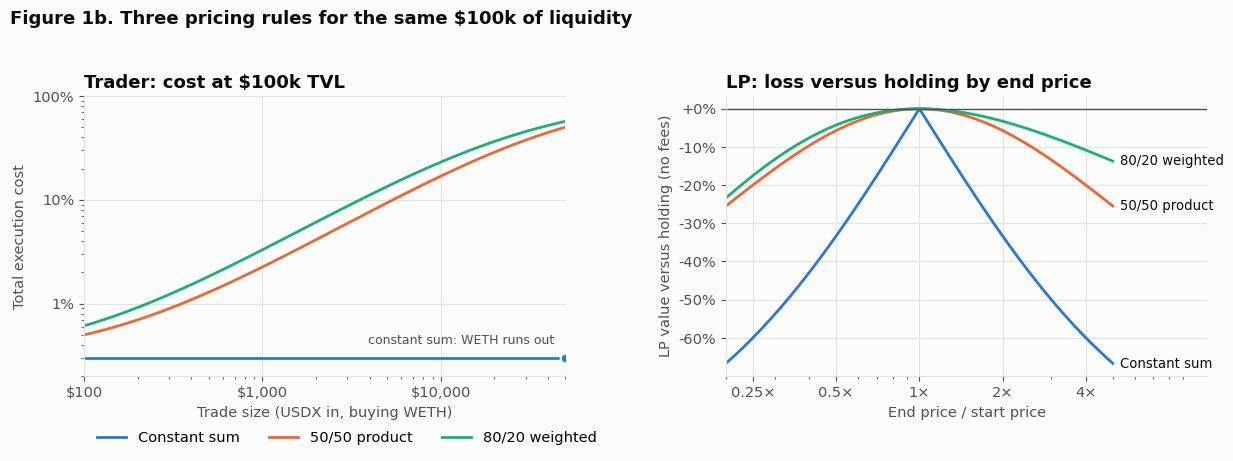

In [8]:
sizes_1b = np.geomspace(100, 50_000, 120)
spot = ETH_PRICE
cost = pd.DataFrame({"trade_usd": sizes_1b})
cost["Constant sum"] = [1 - constant_sum_amount_out(a, y0, spot) * spot / a for a in sizes_1b]
cost["50/50 product"] = [amm.execution_costs(a, x0, y0)["total_cost"] for a in sizes_1b]
cost["80/20 weighted"] = [1 - weighted_amount_out(a, x8, y8, W_USDX, 1 - W_USDX) * spot / a for a in sizes_1b]

ratios_1b = np.geomspace(0.2, 5, 200)
lp = pd.DataFrame({"r": ratios_1b})
lp["Constant sum"] = [lp_vs_hold_constant_sum(r) for r in ratios_1b]
lp["50/50 product"] = [amm.impermanent_loss_closed_form(r) for r in ratios_1b]
lp["80/20 weighted"] = [lp_vs_hold_weighted(r, W_USDX) for r in ratios_1b]

RULES = ["Constant sum", "50/50 product", "80/20 weighted"]
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))
ax = axes[0]
for color, name in zip(SERIES, RULES):
    ax.plot(cost.trade_usd, cost[name], color=color, label=name)
ax.plot([50_000], [0.003], marker="o", color=SERIES[0], markersize=7, markeredgecolor=SURFACE, markeredgewidth=1.5)
ax.annotate("constant sum: WETH runs out", (50_000, 0.003), xytext=(-8, 10), textcoords="offset points",
            ha="right", color=INK_2, fontsize=9)
ax.set_xscale("log"); ax.set_yscale("log")
ax.xaxis.set_major_formatter(usd); ax.yaxis.set_major_formatter(pct)
ax.set_xlim(100, 50_000); ax.set_ylim(0.002, 1)
ax.set_xlabel("Trade size (USDX in, buying WETH)"); ax.set_ylabel("Total execution cost")
ax.set_title("Trader: cost at $100k TVL")

ax = axes[1]
for color, name in zip(SERIES, RULES):
    ax.plot(lp.r, lp[name], color=color, label=name)
    ax.annotate(name, (lp.r.iloc[-1], lp[name].iloc[-1]), xytext=(5, 0), textcoords="offset points",
                va="center", color=INK, fontsize=9.5)
ax.axhline(0, color=INK_2, linewidth=1)
ax.set_xscale("log")
ax.set_xticks([0.25, 0.5, 1, 2, 4]); ax.set_xticklabels(["0.25×", "0.5×", "1×", "2×", "4×"])
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:+.0%}"))
ax.set_xlim(0.2, 5 * 2.2)
ax.set_xlabel("End price / start price"); ax.set_ylabel("LP value versus holding (no fees)")
ax.set_title("LP: loss versus holding by end price")
fig.suptitle("Figure 1b. Three pricing rules for the same $100k of liquidity", x=0.01, ha="left",
             fontsize=13, fontweight="bold", color=INK)
axes[0].legend(loc="upper left", bbox_to_anchor=(0, -0.15), ncol=3)
fig.tight_layout(rect=(0, 0, 1, 0.95))
fig.savefig("figures/fig1b_pricing_rules_compared.png", dpi=200)
plt.show()

**Table 2b.** Cost of a trade in each pool at \$100k TVL. The weighted pool is asymmetric: only 20,000 USDX stands behind a
WETH purchase, and only 32 WETH behind a sale, so both directions are shown.

In [9]:
rows_2b = []
for a in [500, 1_000, 5_000, 10_000]:
    w_in = a / spot   # same value in WETH, selling into the pool
    rows_2b.append({
        "Trade": f"${a:,.0f}",
        "Constant sum": f"{1 - constant_sum_amount_out(a, y0, spot) * spot / a:.2%}",
        "50/50 product": f"{amm.execution_costs(a, x0, y0)['total_cost']:.2%}",
        "80/20, buy WETH": f"{1 - weighted_amount_out(a, x8, y8, W_USDX, 1 - W_USDX) * spot / a:.2%}",
        "80/20, sell WETH": f"{1 - weighted_amount_out(w_in, y8, x8, 1 - W_USDX, W_USDX) / a:.2%}",
    })
pd.DataFrame(rows_2b)

,Trade,Constant sum,50/50 product,"80/20, buy WETH","80/20, sell WETH"
0,$500,0.30%,1.28%,1.82%,1.83%
1,"$1,000",0.30%,2.25%,3.29%,3.33%
2,"$5,000",0.30%,9.34%,13.41%,14.09%
3,"$10,000",0.30%,16.88%,23.06%,25.03%


**Table 2c.** LP value versus holding after the market moves and arbitrageurs rebalance the pool, no fees.

In [10]:
rows_2c = []
for r in [0.5, 0.75, 1.0, 1.5, 2.0]:
    p = r * ETH_PRICE
    cs_reserves = f"{2 * x0:,.0f} USDX / 0 WETH" if r > 1 else f"0 USDX / {2 * y0:.0f} WETH" if r < 1 else f"{x0:,.0f} USDX / {y0:.0f} WETH"
    rows_2c.append({
        "End price": f"{r:.2f}× (${p:,.0f})",
        "Constant sum": f"{lp_vs_hold_constant_sum(r):+.2%}",
        "Constant-sum reserves after": cs_reserves,
        "50/50 product": f"{amm.impermanent_loss_closed_form(r):+.2%}",
        "80/20 weighted": f"{lp_vs_hold_weighted(r, W_USDX):+.2%}",
    })
pd.DataFrame(rows_2c)

,End price,Constant sum,Constant-sum reserves after,50/50 product,80/20 weighted
0,"0.50× ($1,250)",-33.33%,0 USDX / 40 WETH,-5.72%,-4.28%
1,"0.75× ($1,875)",-14.29%,0 USDX / 40 WETH,-1.03%,-0.70%
2,"1.00× ($2,500)",+0.00%,"50,000 USDX / 20 WETH",+0.00%,+0.00%
3,"1.50× ($3,750)",-20.00%,"100,000 USDX / 0 WETH",-2.02%,-1.20%
4,"2.00× ($5,000)",-33.33%,"100,000 USDX / 0 WETH",-5.72%,-3.27%


**Findings**
- *Constant sum* is the best deal for the trader (0.30% all the way up to the whole reserve) and the worst for the LP. Any move
  away from P₀ lets the arbitrageur buy the entire cheaper side at the stale price, so the pool ends holding one asset only:
  −20% versus holding at 1.5× and −33% at 2×, against −2.0% and −5.7% for x·y = k. After that it cannot quote one direction at
  all, so "no curve impact" only holds while the market sits exactly at P₀. The rule fits pegged pairs, and even Curve blends it
  with x·y = k so the reserves cannot be emptied.
- *80/20 weighted* cuts the LP's loss, because 80% of the deposit stays in WETH whatever happens: −3.3% at 2× and −1.2% at 1.5×,
  about 40% less than 50/50. The trader pays for it. With only 20,000 USDX behind the quote, a \$1,000 WETH purchase loses about
  3.0% to the curve instead of 2.0%, and a \$5,000 one about 13% instead of 9%. Weighting the other way (80% USDX) mirrors
  this: it protects the LP in a falling market and makes WETH sales expensive.
- *50/50 constant product* is the middle: reserves never run out, the price adjusts continuously, and for a given TVL it gives
  the lowest curve impact in both directions. For a pool whose purpose is cheap WETH/USDX trading on about \$100k of liquidity
  it is the right default. The weighted rule is a choice an LP-first product might make; the constant-sum rule is not a
  candidate for a volatile pair.

**Limits.** Fee-free LP curves; fees would shift all three up by the same income. The weighted pool here is a float model used
for comparison only; the contract implements x·y = k.

### Shared assumptions for Sections 2 to 6

| Item | Value | Note |
|---|---|---|
| Reference pool | 50,000 USDX + 20 WETH (\$100k TVL) | balanced at 2,500 USDX/WETH |
| Fee split | 0.30% total = 0.25% LPs + 0.05% treasury | high tier 0.50% = 0.45% + 0.05% |
| Gas | 20 gwei, ETH at \$2,500 | swap 120k gas ≈ \$6, add or remove liquidity 150k gas ≈ \$7.5 each |
| Simulation step | 5 minutes, 30 days | arbitrage checks the pool every step |
| Retail flow | \$5,000 per day in 20 trades of \$250, alternating direction | uninformed users; "low volume" case is \$1,000 per day |
| Arbitrage | trades the pool to the external price whenever profitable after the fee | arbitrageurs pay the active fee tier; no cost outside the pool (varied in Table 9b) |
| Chainlink reference | the external price path itself, always fresh | the contract's second fee trigger compares the TWAP with Chainlink |

Gas on Sepolia costs nothing in cash. The gas figures are mainnet-like estimates so the report can say what the same
behaviour would cost real users. Contract gas will be measured in Section 7 once the pool is deployed.

In [11]:
POOL_USDX, POOL_WETH = 50_000.0, 20.0
GAS_PRICE_GWEI, SWAP_GAS, LP_ACTION_GAS = 20, 120_000, 150_000
gas_usd = lambda gas: gas * GAS_PRICE_GWEI * 1e-9 * ETH_PRICE
GAS_SWAP_USD = gas_usd(SWAP_GAS)
GAS_LP_ROUNDTRIP_USD = 2 * gas_usd(LP_ACTION_GAS)
STEP_S, DAYS = 300, 30
N_STEPS = DAYS * 86_400 // STEP_S
RETAIL_PER_DAY, RETAIL_TRADES = 5_000.0, 20
print(f"gas per swap ${GAS_SWAP_USD:.2f}, LP add + remove ${GAS_LP_ROUNDTRIP_USD:.2f}")

gas per swap $6.00, LP add + remove $15.00


## 2. Impermanent loss

**Question.** When the external ETH price moves and arbitrageurs rebalance the pool, how much worse off is an LP than
if they had kept the tokens they deposited?

**Assumptions**
- The reference pool, one LP owning 100% of it.
- The external price moves once to 0.5, 0.75, 1, 1.5 and 2 times its start. An arbitrageur then trades the pool
  until its spot equals the external price (the proposal's "arbitrage-driven rebalancing").
- Base case is fee-free, as in the proposal's definition. A second column keeps the 0.30% fee to show how much a single
  rebalancing trade pays back to the LP.
- Hold value: 50,000 USDX + 20 WETH at the new price. IL = LP value / hold value − 1.
- Closed form for comparison: IL(r) = 2·√r / (1 + r) − 1, with r the price ratio.

In [12]:
RATIOS = [0.5, 0.75, 1.0, 1.5, 2.0]
il_rows = []
for r in RATIOS:
    new_price = ETH_PRICE * r
    hold = POOL_USDX + POOL_WETH * new_price

    pool = amm.Pool.seeded(POOL_USDX, POOL_WETH)            # fee-free rebalancing
    d, res = pool.arbitrage(new_price, fee_bps=0, protocol_fee_bps=0)
    lp_value = pool.pool_value(new_price)
    if d == "usdx_in":
        arb_in, arb_profit = amm.from_wei(res.new_reserve_in - amm.to_wei(POOL_USDX)), amm.from_wei(res.amount_out) * new_price - amm.from_wei(res.new_reserve_in - amm.to_wei(POOL_USDX))
    elif d == "weth_in":
        weth_in = amm.from_wei(res.new_reserve_in - amm.to_wei(POOL_WETH))
        arb_in, arb_profit = weth_in * new_price, amm.from_wei(res.amount_out) - weth_in * new_price
    else:
        arb_in = arb_profit = 0.0

    pool_fee = amm.Pool.seeded(POOL_USDX, POOL_WETH)        # same move, 0.30% fee kept
    pool_fee.arbitrage(new_price, fee_bps=amm.BASE_FEE_BPS, protocol_fee_bps=amm.PROTOCOL_FEE_BPS)

    il_rows.append({
        "Price ratio": r, "New price": new_price, "Arbitrage": d or "none", "Arb trade (USD)": arb_in,
        "USDX reserve": amm.from_wei(pool.reserve_usdx), "WETH reserve": amm.from_wei(pool.reserve_weth),
        "LP value": lp_value, "Hold value": hold, "IL simulated": lp_value / hold - 1,
        "IL closed form": amm.impermanent_loss_closed_form(r), "Arbitrageur profit": arb_profit,
        "LP shortfall": hold - lp_value, "IL with 0.30% fee": pool_fee.pool_value(new_price) / hold - 1,
    })
il = pd.DataFrame(il_rows)
assert np.allclose(il["IL simulated"], il["IL closed form"], atol=1e-9)
assert np.allclose(il["Arbitrageur profit"], il["LP shortfall"], rtol=1e-9)
print("Simulated IL matches the closed form; arbitrageur profit equals the LP shortfall in the fee-free case.")
il_show = il.copy()
for c in ["New price", "Arb trade (USD)", "USDX reserve", "LP value", "Hold value", "Arbitrageur profit", "LP shortfall"]:
    il_show[c] = il_show[c].map(lambda v: f"{v:,.0f}")
il_show["WETH reserve"] = il_show["WETH reserve"].map(lambda v: f"{v:.3f}")
for c in ["IL simulated", "IL closed form", "IL with 0.30% fee"]:
    il_show[c] = il_show[c].map(lambda v: f"{v:+.2%}")
il_show

Simulated IL matches the closed form; arbitrageur profit equals the LP shortfall in the fee-free case.


,Price ratio,New price,Arbitrage,Arb trade (USD),USDX reserve,WETH reserve,LP value,Hold value,IL simulated,IL closed form,Arbitrageur profit,LP shortfall,IL with 0.30% fee
0,0.50,"1,250",weth_in,"10,355","35,355",28.284,"70,711","75,000",-5.72%,-5.72%,"4,289","4,289",-5.68%
1,0.75,"1,875",weth_in,"5,801","43,301",23.094,"86,603","87,500",-1.03%,-1.03%,897,897,-1.01%
2,1.00,"2,500",none,0,"50,000",20.000,"100,000","100,000",+0.00%,+0.00%,0,0,+0.00%
3,1.50,"3,750",usdx_in,"11,237","61,237",16.330,"122,474","125,000",-2.02%,-2.02%,"2,526","2,526",-2.00%
4,2.00,"5,000",usdx_in,"20,711","70,711",14.142,"141,421","150,000",-5.72%,-5.72%,"8,579","8,579",-5.68%


**Table 3.** Impermanent loss after one arbitrage-driven rebalancing. The fee-free simulation reproduces the closed form
to nine decimals, and the arbitrageur's profit is exactly the LP's shortfall: IL is a transfer from LPs to arbitrageurs.

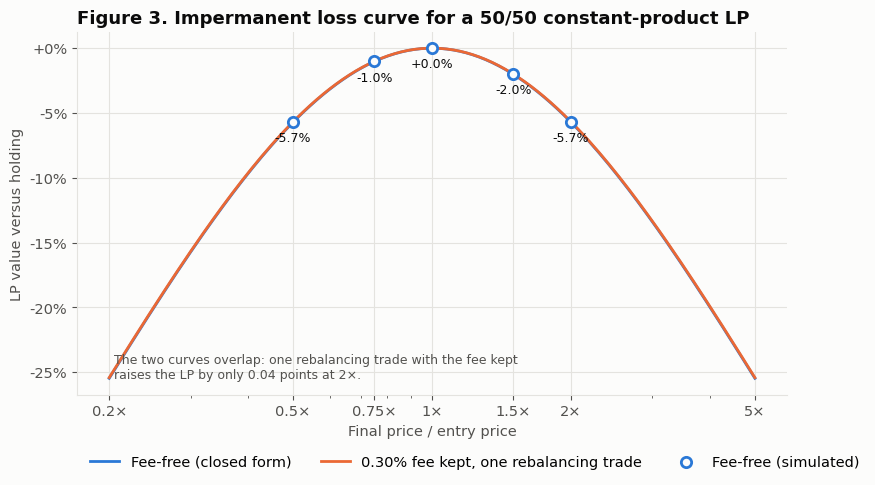

In [13]:
ratios = np.geomspace(0.2, 5, 200)
curve_free = [amm.impermanent_loss_closed_form(r) for r in ratios]
curve_fee = []
for r in ratios:
    p = amm.Pool.seeded(POOL_USDX, POOL_WETH)
    p.arbitrage(ETH_PRICE * r, amm.BASE_FEE_BPS, amm.PROTOCOL_FEE_BPS)
    curve_fee.append(p.pool_value(ETH_PRICE * r) / (POOL_USDX + POOL_WETH * ETH_PRICE * r) - 1)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(ratios, curve_free, color=SERIES[0], label="Fee-free (closed form)")
ax.plot(ratios, curve_fee, color=SERIES[1], label="0.30% fee kept, one rebalancing trade")
ax.scatter(il["Price ratio"], il["IL simulated"], color=SURFACE, edgecolor=SERIES[0], s=55, zorder=3, linewidth=2,
           label="Fee-free (simulated)")
for _, row in il.iterrows():
    ax.annotate(f"{row['IL simulated']:+.1%}", (row["Price ratio"], row["IL simulated"]), xytext=(0, -14),
                textcoords="offset points", ha="center", color=INK, fontsize=9)
ax.text(0.205, -0.235, "The two curves overlap: one rebalancing trade with the fee kept\nraises the LP by only 0.04 points at 2×.",
        color=INK_2, fontsize=9, va="top")
ax.set_xscale("log")
ax.set_xticks([0.2, 0.5, 0.75, 1, 1.5, 2, 5]); ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}×"))
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:+.0%}"))
ax.set_xlabel("Final price / entry price"); ax.set_ylabel("LP value versus holding")
ax.set_title("Figure 3. Impermanent loss curve for a 50/50 constant-product LP")
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.13), ncol=3)
fig.tight_layout(); fig.savefig("figures/fig3_impermanent_loss_curve.png", dpi=200); plt.show()

**Findings**
- IL is symmetric in the log of the price: halving and doubling both cost 5.72%. A 25% move costs about 1%, a 50% move about 2%.
- The loss is real money paid to the arbitrageur who rebalances the pool. In the fee-free case the two amounts match exactly.
- One rebalancing trade with the 0.30% fee kept recovers only a small slice of the loss (about 0.05 points at 2×). Fees can offset
  IL only through repeated volume, which is what Section 3 measures.
- The front end's LP dashboard can use the closed form directly; it is exact for a single price move and matches the contract math.

## 3. LP profitability

**Question.** Do retained fees pay for impermanent loss and gas, and how does that depend on the LP's share, the price path and the volume?

### 3a. Same pool, same period: fees follow shares

**Assumptions.** Four LPs fund the reference pool: the team seed of \$38k and three users with \$2k, \$10k and \$50k. In one
month the pool collects a fixed LP fee total of \$300 (0.25% of \$120k routed volume). Fees are allocated in proportion to
LP shares; each user pays one add and one remove (\$15 of gas at the shared assumptions).

In [14]:
pool = amm.Pool(0, 0)
deposits = {"Team seed": 38_000, "LP A": 2_000, "LP B": 10_000, "LP C": 50_000}
shares = {name: pool.add_liquidity(amm.to_wei(d / 2), amm.to_wei(d / 2 / ETH_PRICE)) for name, d in deposits.items()}
FEE_POOL_TOTAL = 300.0
rows = []
for name, d in deposits.items():
    share = shares[name] / pool.total_shares
    fees = FEE_POOL_TOTAL * share
    gas = 0.0 if name == "Team seed" else GAS_LP_ROUNDTRIP_USD
    rows.append({"LP": name, "Deposit": f"${d:,.0f}", "Pool share": f"{share:.1%}", "Allocated fees": f"${fees:,.2f}",
                 "Gas (add + remove)": f"${gas:,.2f}", "Net fee income": f"${fees - gas:,.2f}",
                 "Monthly yield after gas": f"{(fees - gas) / d:+.2%}"})
assert abs(sum(shares.values()) / pool.total_shares - 1) < 1e-12
pd.DataFrame(rows)

,LP,Deposit,Pool share,Allocated fees,Gas (add + remove),Net fee income,Monthly yield after gas
0,Team seed,"$38,000",38.0%,$114.00,$0.00,$114.00,+0.30%
1,LP A,"$2,000",2.0%,$6.00,$15.00,$-9.00,-0.45%
2,LP B,"$10,000",10.0%,$30.00,$15.00,$15.00,+0.15%
3,LP C,"$50,000",50.0%,$150.00,$15.00,$135.00,+0.27%


**Table 4.** A larger deposit earns a proportionally larger slice of the same fee pool. Gas is the same for every LP, so the
\$2k deposit's yield after gas is far below the \$50k deposit's. This is the proportional-fee example for the campaign page.

### 3b. Price path, volume and deposit size

**Assumptions**
- Three 30-day price paths, each pinned to a chosen end point so scenarios stay comparable:
  *calm sideways* (40% annualised volatility, ends at 1.0×), *volatile sideways* (100%, ends at 1.0×), *trend up* (60%, ends at 1.5×).
- Retail flow of \$5,000 per day as in the shared assumptions; arbitrageurs keep the pool near the external price and pay the 0.30% fee.
- The LP being evaluated holds 2%, 10% or 50% of the reference pool (\$2k, \$10k, \$50k). Fees and IL scale with the share.
- Net P&L versus holding = LP value − hold value − gas, with LP value including the fees retained in the pool.
- Historical ETH prices alone do not determine fee income: the fee comes from the assumed order flow, so the volume sensitivity below matters as much as the path.

In [15]:
SCENARIOS = {
    "Calm sideways (40% vol, 1.0×)": dict(sigma=0.40, end=1.0, seed=11),
    "Volatile sideways (100% vol, 1.0×)": dict(sigma=1.00, end=1.0, seed=12),
    "Trend up (60% vol, 1.5×)": dict(sigma=0.60, end=1.5, seed=13),
}
paths = {name: amm.gbm_path(N_STEPS, STEP_S, s["sigma"], s["end"], s["seed"], start=ETH_PRICE) for name, s in SCENARIOS.items()}

def run(name, **overrides):
    kw = dict(step_s=STEP_S, retail_volume_per_day=RETAIL_PER_DAY, retail_trades_per_day=RETAIL_TRADES)
    kw.update(overrides)
    cfg = amm.SimConfig(**kw)
    return amm.simulate(paths[name], amm.Pool.seeded(POOL_USDX, POOL_WETH), cfg)

fixed = {name: run(name) for name in SCENARIOS}

def summary(df):
    last = df.iloc[-1]
    return {
        "arb_volume": df.arb_volume.sum(), "retail_volume": df.retail_volume.sum(), "retail_cost": df.retail_cost.sum(),
        "lp_fees": last.lp_fees, "il": last.pool_value - last.lp_fees - last.hold_value,
        "pnl_vs_hold": last.pool_value - last.hold_value, "protocol_revenue": last.protocol_revenue,
        "high_share": df.high_tier.mean(), "end_price": last.price,
    }

lp_rows = []
for name, df in fixed.items():
    s = summary(df)
    for deposit in [2_000, 10_000, 50_000]:
        share = deposit / (POOL_USDX * 2)
        fees, il_usd = s["lp_fees"] * share, s["il"] * share
        net = fees + il_usd - GAS_LP_ROUNDTRIP_USD
        lp_rows.append({"Scenario": name, "Deposit": f"${deposit:,.0f}", "Fees earned": f"${fees:,.2f}",
                        "IL (value vs hold, ex fees)": f"${il_usd:,.2f}", "Gas": f"${GAS_LP_ROUNDTRIP_USD:,.2f}",
                        "Net vs holding": f"${net:,.2f}", "Net / deposit": f"{net / deposit:+.2%}"})
pd.DataFrame(lp_rows)

,Scenario,Deposit,Fees earned,"IL (value vs hold, ex fees)",Gas,Net vs holding,Net / deposit
0,"Calm sideways (40% vol, 1.0×)","$2,000",$15.34,$-0.03,$15.00,$0.31,+0.02%
1,"Calm sideways (40% vol, 1.0×)","$10,000",$76.69,$-0.15,$15.00,$61.54,+0.62%
2,"Calm sideways (40% vol, 1.0×)","$50,000",$383.45,$-0.75,$15.00,$367.70,+0.74%
3,"Volatile sideways (100% vol, 1.0×)","$2,000",$23.68,$-0.05,$15.00,$8.63,+0.43%
4,"Volatile sideways (100% vol, 1.0×)","$10,000",$118.40,$-0.26,$15.00,$103.14,+1.03%
5,"Volatile sideways (100% vol, 1.0×)","$50,000",$592.00,$-1.31,$15.00,$575.69,+1.15%
6,"Trend up (60% vol, 1.5×)","$2,000",$19.63,$-50.59,$15.00,$-45.96,-2.30%
7,"Trend up (60% vol, 1.5×)","$10,000",$98.16,$-252.94,$15.00,$-169.78,-1.70%
8,"Trend up (60% vol, 1.5×)","$50,000",$490.80,"$-1,264.68",$15.00,$-788.89,-1.58%


**Table 5.** LP result after 30 days by scenario and deposit size, fixed 0.30% fee.

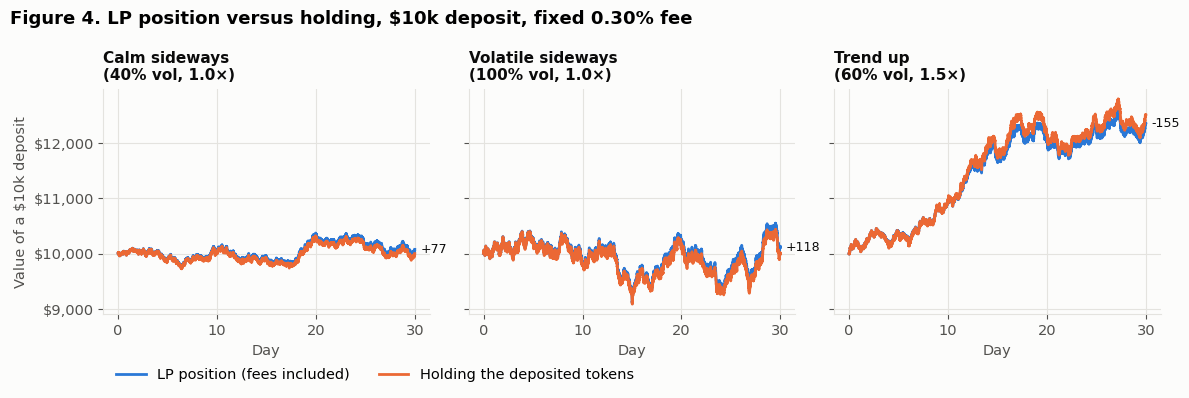

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4.2), sharey=True)
days = fixed[next(iter(fixed))].t_s / 86_400
for ax, (name, df) in zip(axes, fixed.items()):
    share = 10_000 / (POOL_USDX * 2)
    ax.plot(days, df.pool_value * share, color=SERIES[0], label="LP position (fees included)")
    ax.plot(days, df.hold_value * share, color=SERIES[1], label="Holding the deposited tokens")
    ax.set_title(name.split(" (")[0] + "\n" + "(" + name.split(" (")[1], fontsize=11)
    ax.set_xlabel("Day"); ax.xaxis.set_major_locator(plt.MultipleLocator(10))
    ax.yaxis.set_major_formatter(usd)
    end_lp, end_hold = df.pool_value.iloc[-1] * share, df.hold_value.iloc[-1] * share
    ax.annotate(f"{end_lp - end_hold:+,.0f}", (days.iloc[-1], end_lp), xytext=(4, 0), textcoords="offset points",
                va="center", color=INK, fontsize=9)
axes[0].set_ylabel("Value of a $10k deposit")
fig.suptitle("Figure 4. LP position versus holding, $10k deposit, fixed 0.30% fee", x=0.01, ha="left", fontsize=13, fontweight="bold")
axes[0].legend(loc="upper left", bbox_to_anchor=(0, -0.18), ncol=2)
fig.tight_layout(); fig.subplots_adjust(wspace=0.12); fig.savefig("figures/fig4_lp_vs_hold_paths.png", dpi=200); plt.show()

In [17]:
vol_rows = []
for daily in [0, 1_000, 5_000, 20_000]:
    for name in SCENARIOS:
        df = run(name, retail_volume_per_day=float(daily))
        s = summary(df)
        share = 10_000 / (POOL_USDX * 2)
        net = s["pnl_vs_hold"] * share - GAS_LP_ROUNDTRIP_USD
        vol_rows.append({"Retail volume / day": f"${daily:,.0f}", "Scenario": name.split(" (")[0],
                         "Arb volume (30d)": f"${s['arb_volume']:,.0f}", "Fees to LPs (pool)": f"${s['lp_fees']:,.0f}",
                         "$10k LP net vs holding": f"${net:,.2f}"})
pd.DataFrame(vol_rows).pivot(index="Retail volume / day", columns="Scenario", values="$10k LP net vs holding").reindex(
    [f"${d:,.0f}" for d in [0, 1_000, 5_000, 20_000]])

Scenario,Calm sideways,Trend up,Volatile sideways
Retail volume / day,,,
$0,$-3.26,$-239.56,$39.93
"$1,000",$5.61,$-229.25,$49.03
"$5,000",$61.54,$-169.78,$103.14
"$20,000",$287.71,$75.53,$332.19


**Table 6.** Net result of a \$10k LP versus holding (after \$15 gas) as retail volume varies. With no retail flow the only
counterparty is the arbitrageur, so the LP's fee income is exactly the fee paid on trades that move the pool against them.

**Findings**
- With \$5k a day of retail flow the \$100k pool earned \$767 to \$1,184 of LP fees in 30 days (0.8% to 1.2% of TVL). Roughly half came from arbitrageurs, half from retail; the volatile path paid most because arbitrageurs traded most.
- Sideways markets favour the LP: a \$10k deposit finished \$62 to \$103 ahead of holding after gas (+0.6% to +1.0% for the month). IL is near zero because the price ends where it started.
- A sustained move is what hurts. In the trend-up path the \$10k LP lost \$253 to IL (the closed-form 2.0% of the \$12.5k hold value) against \$98 of fees, finishing 1.7% behind holding. Retail flow would have to exceed about \$20k a day for that LP to break even.
- Gas is the whole margin for small deposits: the \$2k LP earns \$15 to \$24 a month in fees against \$15 of gas. On Sepolia the gas is free, which is why the campaign can invite small LPs there.
- With no retail flow at all, fees from arbitrage alone roughly cover gas in a sideways market, but an arbitrageur who pays 0.30% still takes far more than that out of the pool in a trend.

## 4. Fixed versus dynamic fees

**Question.** Does the contract's 0.30% / 0.50% tier help LPs, and what does it cost traders and the protocol?

**The rule as deployed** (`AMMPool.getDynamicFeeStatus`, main). After the 30-minute TWAP warm-up the fee for a swap is read
*before* the trade executes and is 0.50% if either signal fires, otherwise 0.30%:

| Signal | Test | Note |
|---|---|---|
| Spot versus TWAP | \|spot / TWAP − 1\| ≥ 1% | pool-internal, always available |
| TWAP versus Chainlink | \|TWAP / Chainlink − 1\| ≥ 1% | only while the feed is fresh (≤ 90 min old); a stale or unavailable feed switches this signal off, swaps continue |

During warm-up the fee is 0.30% and the oracle is not read. The thresholds and fee levels are Solidity constants.
Traders can call the `WithFeeCap` entry points and have the swap revert if the fee is above their cap.

**Assumptions**
- Same three price paths and the same retail flow as Section 3, so the comparison is on matched paths and flows. The external price path also stands in for Chainlink.
- TWAP: 30-minute time-weighted average of the pool spot; the base tier applies during warm-up, as in the contract.
- Policies compared: fixed 0.30%; the contract rule; the spot/TWAP signal alone (what the earlier draft of this notebook modelled); the contract rule with elastic demand (half of the retail trades that meet 0.50% walk away, as a fee cap lets them); and a what-if that reads the tier from the spot the trade would *leave*, so the trade that moves the price is the one that pays more.
- Triggers are varied to 0.5% and 2% in Table 8 (both signals moved together).
- Trader cost = fee + curve impact + any pool mispricing, measured against the external price, summed over retail trades.

In [18]:
def policy_table(names, policies, retail=RETAIL_PER_DAY):
    rows = []
    for name in names:
        for label, kw in policies.items():
            s = summary(run(name, retail_volume_per_day=retail, **kw))
            rows.append({"Scenario": name.split(" (")[0], "Fee policy": label, "Steps with a 0.50% trade": f"{s['high_share']:.1%}",
                         "Retail volume": f"${s['retail_volume']:,.0f}", "Trader cost": f"${s['retail_cost']:,.0f}",
                         "Trader cost %": f"{s['retail_cost'] / max(s['retail_volume'], 1):.2%}",
                         "Arb volume": f"${s['arb_volume']:,.0f}", "LP fees": f"${s['lp_fees']:,.0f}",
                         "LP P&L vs hold": f"${s['pnl_vs_hold']:+,.0f}", "Protocol revenue": f"${s['protocol_revenue']:,.0f}",
                         "_pnl": s["pnl_vs_hold"], "_rev": s["protocol_revenue"]})
    return pd.DataFrame(rows)

POLICIES = {"Fixed 0.30%": dict(),
            "Contract rule (both signals, 1%)": dict(dynamic_fee=True, trigger=0.01, chainlink_trigger=0.01),
            "Spot/TWAP signal only, 1%": dict(dynamic_fee=True, trigger=0.01, chainlink_trigger=None),
            "Contract rule, elastic demand": dict(dynamic_fee=True, trigger=0.01, chainlink_trigger=0.01, demand_drop_at_high_fee=0.5),
            "What-if: tier on post-trade spot": dict(dynamic_fee=True, trigger=0.01, chainlink_trigger=0.01, tier_on_post_trade=True)}
pol = policy_table(SCENARIOS, POLICIES)
pol.drop(columns=["_pnl", "_rev"])

,Scenario,Fee policy,Steps with a 0.50% trade,Retail volume,Trader cost,Trader cost %,Arb volume,LP fees,LP P&L vs hold,Protocol revenue
0,Calm sideways,Fixed 0.30%,0.0%,"$154,250","$1,156",0.75%,"$152,331",$767,$+765,$153
1,Calm sideways,"Contract rule (both signals, 1%)",0.6%,"$154,250","$1,154",0.75%,"$151,903",$771,$+770,$153
2,Calm sideways,"Spot/TWAP signal only, 1%",0.5%,"$154,250","$1,154",0.75%,"$151,903",$771,$+770,$153
3,Calm sideways,"Contract rule, elastic demand",0.6%,"$154,250","$1,154",0.75%,"$151,903",$771,$+770,$153
4,Calm sideways,What-if: tier on post-trade spot,3.7%,"$154,250","$1,314",0.85%,"$152,252",$927,$+925,$153
5,Volatile sideways,Fixed 0.30%,0.0%,"$154,250","$1,214",0.79%,"$312,971","$1,184","$+1,181",$237
6,Volatile sideways,"Contract rule (both signals, 1%)",12.3%,"$154,250","$1,236",0.80%,"$295,758","$1,327","$+1,324",$228
7,Volatile sideways,"Spot/TWAP signal only, 1%",2.9%,"$154,250","$1,223",0.79%,"$310,088","$1,218","$+1,216",$235
8,Volatile sideways,"Contract rule, elastic demand",12.1%,"$147,250","$1,217",0.83%,"$296,284","$1,296","$+1,293",$225
9,Volatile sideways,What-if: tier on post-trade spot,13.7%,"$154,250","$1,378",0.89%,"$297,934","$1,452","$+1,448",$229


**Table 7.** Fixed versus dynamic fee on matched paths and flows, whole pool, 30 days.

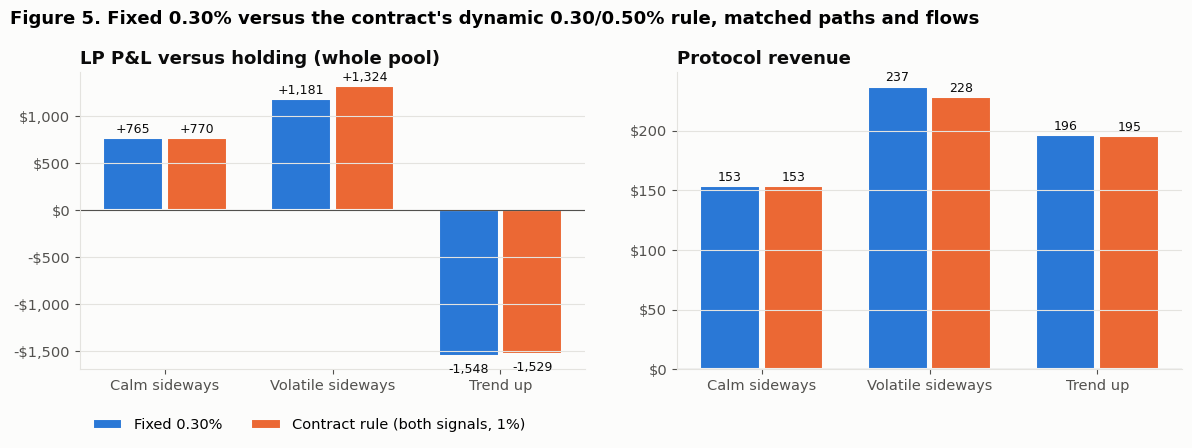

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
scen = [n.split(" (")[0] for n in SCENARIOS]
width = 0.38
x = np.arange(len(scen))
two = list(POLICIES)[:2]
for ax, metric, title in [(axes[0], "_pnl", "LP P&L versus holding (whole pool)"), (axes[1], "_rev", "Protocol revenue")]:
    for j, label in enumerate(two):
        vals = [pol[(pol.Scenario == s) & (pol["Fee policy"] == label)][metric].iloc[0] for s in scen]
        bars = ax.bar(x + (j - 0.5) * width, vals, width * 0.94, color=SERIES[j], label=label, edgecolor=SURFACE, linewidth=1.5)
        for b, v in zip(bars, vals):
            ax.annotate(f"{v:+,.0f}" if metric == "_pnl" else f"{v:,.0f}", (b.get_x() + b.get_width() / 2, v),
                        xytext=(0, 4 if v >= 0 else -12), textcoords="offset points", ha="center", color=INK, fontsize=9)
    ax.set_xticks(x); ax.set_xticklabels(scen); ax.yaxis.set_major_formatter(usd); ax.set_title(title)
    ax.axhline(0, color=INK_2, linewidth=0.8); ax.grid(axis="x", visible=False)
fig.suptitle("Figure 5. Fixed 0.30% versus the contract's dynamic 0.30/0.50% rule, matched paths and flows", x=0.01, ha="left", fontsize=13, fontweight="bold")
axes[0].legend(loc="upper left", bbox_to_anchor=(0, -0.12), ncol=2)
fig.tight_layout(); fig.savefig("figures/fig5_fixed_vs_dynamic_fee.png", dpi=200); plt.show()

In [20]:
vol_name = [n for n in SCENARIOS if n.startswith("Volatile")][0]
TRIGGERS = [0.005, 0.01, 0.02]
trig = policy_table([vol_name], {
    **{f"Contract rule, {t:.1%}": dict(dynamic_fee=True, trigger=t, chainlink_trigger=t) for t in TRIGGERS},
    **{f"Spot/TWAP only, {t:.1%}": dict(dynamic_fee=True, trigger=t, chainlink_trigger=None) for t in TRIGGERS},
    **{f"Contract rule, {t:.1%}, elastic demand": dict(dynamic_fee=True, trigger=t, chainlink_trigger=t, demand_drop_at_high_fee=0.5) for t in TRIGGERS},
    **{f"What-if post-trade, {t:.1%}": dict(dynamic_fee=True, trigger=t, chainlink_trigger=t, tier_on_post_trade=True) for t in TRIGGERS},
})
trig.drop(columns=["Scenario", "_pnl", "_rev"])

,Fee policy,Steps with a 0.50% trade,Retail volume,Trader cost,Trader cost %,Arb volume,LP fees,LP P&L vs hold,Protocol revenue
0,"Contract rule, 0.5%",54.1%,"$154,250","$1,332",0.86%,"$247,294","$1,605","$+1,602",$204
1,"Contract rule, 1.0%",12.3%,"$154,250","$1,236",0.80%,"$295,758","$1,327","$+1,324",$228
2,"Contract rule, 2.0%",0.0%,"$154,250","$1,214",0.79%,"$312,873","$1,185","$+1,182",$237
3,"Spot/TWAP only, 0.5%",21.9%,"$154,250","$1,273",0.83%,"$293,943","$1,385","$+1,383",$227
4,"Spot/TWAP only, 1.0%",2.9%,"$154,250","$1,223",0.79%,"$310,088","$1,218","$+1,216",$235
5,"Spot/TWAP only, 2.0%",0.0%,"$154,250","$1,214",0.79%,"$312,971","$1,184","$+1,181",$237
6,"Contract rule, 0.5%, elastic demand",53.1%,"$114,500",$971,0.85%,"$228,179","$1,343","$+1,341",$174
7,"Contract rule, 1.0%, elastic demand",12.1%,"$147,250","$1,217",0.83%,"$296,284","$1,296","$+1,293",$225
8,"Contract rule, 2.0%, elastic demand",0.0%,"$154,250","$1,214",0.79%,"$312,873","$1,185","$+1,182",$237
9,"What-if post-trade, 0.5%",50.5%,"$154,250","$1,488",0.96%,"$253,862","$1,695","$+1,691",$207


**Table 8.** Trigger sensitivity in the volatile scenario, both thresholds moved together. A tighter trigger puts the pool in the high tier more often.

In [21]:
low = policy_table(SCENARIOS, {k: POLICIES[k] for k in list(POLICIES)[:2]}, retail=1_000.0)
low.drop(columns=["_pnl", "_rev"])

,Scenario,Fee policy,Steps with a 0.50% trade,Retail volume,Trader cost,Trader cost %,Arb volume,LP fees,LP P&L vs hold,Protocol revenue
0,Calm sideways,Fixed 0.30%,0.0%,"$30,850",$117,0.38%,"$51,486",$206,$+206,$41
1,Calm sideways,"Contract rule (both signals, 1%)",0.0%,"$30,850",$117,0.38%,"$51,486",$206,$+206,$41
2,Volatile sideways,Fixed 0.30%,0.0%,"$30,850",$120,0.39%,"$221,932",$641,$+640,$128
3,Volatile sideways,"Contract rule (both signals, 1%)",9.4%,"$30,850",$125,0.41%,"$209,330",$723,$+722,$122
4,Trend up,Fixed 0.30%,0.0%,"$30,850",$121,0.39%,"$111,253",$382,"$-2,142",$76
5,Trend up,"Contract rule (both signals, 1%)",0.9%,"$30,850",$122,0.39%,"$110,261",$389,"$-2,136",$76


**Table 9.** Low-volume case: retail flow of \$1,000 per day instead of \$5,000.

In [22]:
ARB_COSTS = [0.0, 0.001, 0.003]
arb = policy_table([n for n in SCENARIOS if not n.startswith("Calm")], {
    **{f"Fixed 0.30%, arb cost {c:.1%}": dict(arb_extra_cost=c) for c in ARB_COSTS},
    **{f"Contract rule, arb cost {c:.1%}": dict(dynamic_fee=True, trigger=0.01, chainlink_trigger=0.01, arb_extra_cost=c) for c in ARB_COSTS},
})
arb.drop(columns=["Retail volume", "Trader cost", "_pnl", "_rev"])

,Scenario,Fee policy,Steps with a 0.50% trade,Trader cost %,Arb volume,LP fees,LP P&L vs hold,Protocol revenue
0,Volatile sideways,"Fixed 0.30%, arb cost 0.0%",0.0%,0.79%,"$312,971","$1,184","$+1,181",$237
1,Volatile sideways,"Fixed 0.30%, arb cost 0.1%",0.0%,0.78%,"$266,867","$1,067","$+1,065",$213
2,Volatile sideways,"Fixed 0.30%, arb cost 0.3%",0.0%,0.74%,"$200,625",$900,$+898,$180
3,Volatile sideways,"Contract rule, arb cost 0.0%",12.3%,0.80%,"$295,758","$1,327","$+1,324",$228
4,Volatile sideways,"Contract rule, arb cost 0.1%",14.7%,0.80%,"$248,901","$1,219","$+1,216",$204
5,Volatile sideways,"Contract rule, arb cost 0.3%",20.1%,0.75%,"$178,601","$1,076","$+1,074",$169
6,Trend up,"Fixed 0.30%, arb cost 0.0%",0.0%,0.73%,"$208,120",$982,"$-1,548",$196
7,Trend up,"Fixed 0.30%, arb cost 0.1%",0.0%,0.70%,"$171,127",$881,"$-1,647",$176
8,Trend up,"Fixed 0.30%, arb cost 0.3%",0.0%,0.59%,"$111,134",$718,"$-1,809",$144
9,Trend up,"Contract rule, arb cost 0.0%",1.7%,0.73%,"$205,990","$1,000","$-1,529",$195


**Table 9b.** Arbitrageur with costs outside the pool (venue fee plus slippage of 0, 0.1% or 0.3% of the external leg), as in the
front end's pool-arbitrage research tool. A costlier arbitrageur leaves the pool further from the market before trading.

**Findings**
- The Chainlink signal does most of the work. With the spot/TWAP signal alone the 0.50% tier is active in 0.5% to 2.9% of steps; the contract's two-signal rule reaches 12.3% in the volatile path (0.6% calm, 1.7% trend). The 30-minute TWAP lags a fast market by about half a window, so a 1% TWAP-versus-Chainlink gap opens far more often than a 1% spot-versus-TWAP gap.
- Effect on LPs: in the volatile path LP P&L rises from \$1,181 (fixed) to \$1,324 (+12%); the spot/TWAP-only rule gives \$1,216 (+3%). Calm and trend paths move by under 1%, and no fee rule changes the trend-path loss: IL from a sustained move is the same under every policy. Figure 5 shows LP P&L and protocol revenue side by side.
- Cost to traders: retail cost rises from 0.79% to 0.80% of volume in the volatile path and is unchanged elsewhere. Arbitrageurs, who pay 0.50% more often, trade \$17k (5%) less, so the pool sits slightly further from the market and protocol revenue slips 4% (\$237 to \$228). With a fee cap and elastic demand, 4.5% of retail volume walks away and protocol revenue falls 5%.
- The pre-trade read still charges the wrong trade: the arbitrage order that opens the gap pays 0.30% and the trades after it pay 0.50%. Reading the tier from the post-trade spot would lift volatile-path LP P&L to \$1,448 (+23%), but a \$250 retail order already moves a \$100k pool by 1%, so retail pays 0.50% even in the calm path (LP fees \$767 to \$927, trader cost 0.75% to 0.85%). Not recommended for a pool this thin.
- Trigger sensitivity (Table 8): at 0.5% the pool is in the high tier 54% of the time; LP P&L +36% but trader cost 0.86%, protocol revenue −14%, and with elastic demand retail volume −26% and protocol revenue −27%. At 2% the rule never fires. 1% is the defensible setting.
- Low volume (Table 9): same pattern, smaller numbers; the rule adds \$82 (13%) to volatile-path LP P&L at \$1,000 a day of retail flow.
- Arbitrageur costs (Table 9b): an arbitrageur who pays 0.3% outside the pool trades 36% less, LP fees fall 24% (\$1,184 to \$900) and the high tier is active 20% of the time instead of 12%, because the pool sits further from the market. In the trend path the LP ends \$261 worse: the same IL with less fee income. Section 3's LP returns assume frictionless arbitrage and are an upper bound on fee income from that source.
- Recommendation: keep the deployed rule (both signals, 1%, pre-trade read). It is a modest LP benefit in volatile markets at almost no cost to traders, and the "1% is illustrative" note in the front end can be replaced with this result. For the Sepolia demo see the operational note in Section 7b: without arbitrageurs the TWAP/Chainlink signal will keep the pool at 0.50% once the market has moved 1% from the seeding price.

## 5. Trader paper trading and backtest

**Question.** What does a simple dollar-cost-averaging (DCA) rule return when every order is filled by this pool, with fee, price impact and gas, compared with holding?

**Assumptions**
- Reference prices: Kraken ETH/USD hourly closes for the last 30 days (`data/eth_usd_hourly_kraken.csv`, retrieved 2026-10-28). USDX is taken as 1 USD.
- The pool is the reference pool. Before each order an arbitrageur moves it to the current close (paying 0.30%), so fills reflect the live price plus this pool's own costs.
- DCA rule: start with 10,000 USDX; every 24 hours buy an equal slice so the capital is spent over the 30 days. Orders execute at the close of the hour in which they are decided; no later information is used.
- Costs per order: 0.30% fee, curve impact from the integer swap, \$6 gas. Idle cash is included in portfolio value.
- Benchmarks: *hold* buys all 10,000 USDX of WETH through the pool at the first close (one order, one gas charge); *reference DCA* is the same schedule at the external price with no costs, to isolate what the pool costs the strategy.
- Variants: order every 1, 3 and 7 days.

In [23]:
candles = pd.read_csv("data/eth_usd_hourly_kraken.csv")
candles = candles.iloc[:-1]                           # drop the candle still in progress at retrieval
candles["time"] = pd.to_datetime(candles["time_utc"], utc=True)
closes = candles["close"].to_numpy()
print(f"{len(candles)} hourly closes, {candles.time.iloc[0]:%Y-%m-%d} to {candles.time.iloc[-1]:%Y-%m-%d %H:%M} UTC, "
      f"{closes[0]:,.0f} -> {closes[-1]:,.0f} USD ({closes[-1] / closes[0] - 1:+.1%})")

def backtest_dca(closes, capital, interval_hours, fee_bps=amm.BASE_FEE_BPS, gas=GAS_SWAP_USD, through_pool=True):
    pool = amm.Pool.seeded(POOL_USDX * closes[0] / ETH_PRICE, POOL_WETH)   # seeded balanced at the first close
    order_idx = list(range(0, len(closes), interval_hours))
    slice_usd = capital / len(order_idx)
    cash, units, fees, impact, gas_paid = capital, 0.0, 0.0, 0.0, 0.0
    values = []
    for i, p in enumerate(closes):
        if i in order_idx:
            if through_pool:
                pool.arbitrage(p, amm.BASE_FEE_BPS, amm.PROTOCOL_FEE_BPS)
                r = pool.swap_usdx_in(amm.to_wei(slice_usd), fee_bps, amm.PROTOCOL_FEE_BPS)
                got = amm.from_wei(r.amount_out)
                fees += slice_usd * fee_bps / amm.BPS
                impact += slice_usd * (1 - fee_bps / amm.BPS) - got * p
                gas_paid += gas
                cash -= slice_usd + gas
            else:
                got = slice_usd / p
                cash -= slice_usd
            units += got
        values.append(cash + units * p)
    values = np.array(values)
    peak = np.maximum.accumulate(values)
    return {"values": values, "final": values[-1], "return": values[-1] / capital - 1,
            "max_drawdown": float(((values - peak) / peak).min()), "orders": len(order_idx),
            "fees": fees, "impact": impact, "gas": gas_paid, "units": units}

CAPITAL = 10_000.0
dca = {h: backtest_dca(closes, CAPITAL, h) for h in [24, 72, 168]}
hold = backtest_dca(closes, CAPITAL, len(closes))            # a single order at the first close
ref_dca = backtest_dca(closes, CAPITAL, 24, through_pool=False)
ref_hold = backtest_dca(closes, CAPITAL, len(closes), through_pool=False)
bt_rows = []
for label, r in [("DCA daily (30 orders)", dca[24]), ("DCA every 3 days", dca[72]), ("DCA weekly", dca[168]),
                 ("Hold: buy all at start through the pool", hold), ("Reference DCA daily, no costs", ref_dca),
                 ("Reference hold, no costs", ref_hold)]:
    bt_rows.append({"Strategy": label, "Orders": r["orders"], "WETH held": f"{r['units']:.4f}", "Final value": f"${r['final']:,.2f}",
                    "Net return": f"{r['return']:+.2%}", "Max drawdown": f"{r['max_drawdown']:.2%}",
                    "Fees": f"${r['fees']:,.2f}", "Curve impact": f"${r['impact']:,.2f}", "Gas": f"${r['gas']:,.2f}",
                    "All costs / capital": f"{(r['fees'] + r['impact'] + r['gas']) / CAPITAL:.2%}"})
pd.DataFrame(bt_rows)

720 hourly closes, 2026-09-28 to 2026-10-28 22:00 UTC, 2,687 -> 2,359 USD (-12.2%)


,Strategy,Orders,WETH held,Final value,Net return,Max drawdown,Fees,Curve impact,Gas,All costs / capital
0,DCA daily (30 orders),30,3.9490,"$9,133.96",-8.66%,-10.70%,$30.00,$87.42,$180.00,2.97%
1,DCA every 3 days,10,3.8782,"$9,086.94",-9.13%,-11.36%,$30.00,$213.02,$60.00,3.03%
2,DCA weekly,5,3.8257,"$8,993.12",-10.07%,-11.93%,$30.00,$390.35,$30.00,4.50%
3,Hold: buy all at start through the pool,1,3.1294,"$7,374.73",-26.25%,-16.57%,$30.00,"$1,559.99",$6.00,15.96%
4,"Reference DCA daily, no costs",30,3.9960,"$9,424.79",-5.75%,-8.35%,$0.00,$0.00,$0.00,0.00%
5,"Reference hold, no costs",1,3.7210,"$8,776.13",-12.24%,-16.56%,$0.00,$0.00,$0.00,0.00%


**Table 10.** DCA through the pool versus holding, 10,000 USDX over the last 30 days.

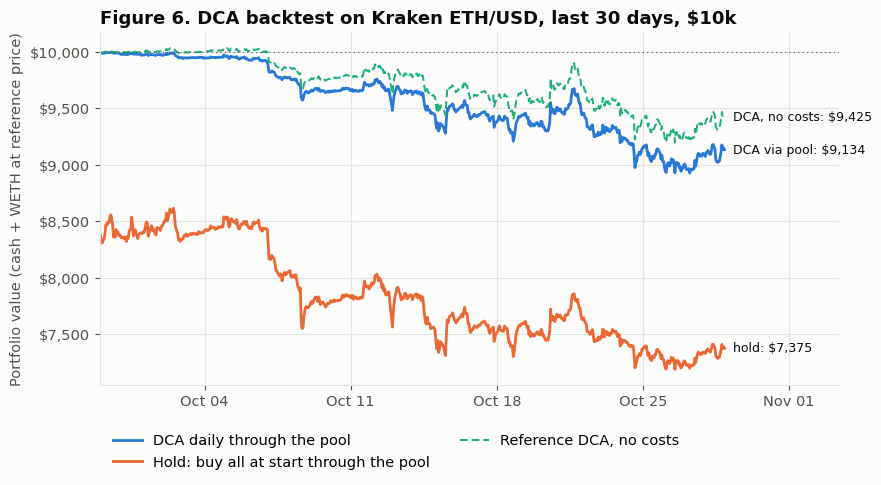

In [24]:
fig, ax = plt.subplots(figsize=(9, 5))
t = candles["time"]
ax.plot(t, dca[24]["values"], color=SERIES[0], label="DCA daily through the pool")
ax.plot(t, hold["values"], color=SERIES[1], label="Hold: buy all at start through the pool")
ax.plot(t, ref_dca["values"], color=SERIES[2], label="Reference DCA, no costs", linewidth=1.4, linestyle=(0, (4, 2)))
for r, color, label in [(dca[24], SERIES[0], "DCA via pool"), (hold, SERIES[1], "hold"), (ref_dca, SERIES[2], "DCA, no costs")]:
    ax.annotate(f"{label}: ${r['final']:,.0f}", (t.iloc[-1], r["final"]), xytext=(6, 0), textcoords="offset points",
                va="center", color=INK, fontsize=9)
ax.axhline(CAPITAL, color=INK_2, linewidth=0.8, linestyle=(0, (1, 3)))
ax.yaxis.set_major_formatter(usd); ax.set_ylabel("Portfolio value (cash + WETH at reference price)")
ax.set_xlim(t.iloc[0], t.iloc[-1] + pd.Timedelta(days=5.5))
import matplotlib.dates as mdates
ax.xaxis.set_major_locator(mdates.DayLocator(interval=7)); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax.set_title("Figure 6. DCA backtest on Kraken ETH/USD, last 30 days, $10k")
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.1), ncol=2)
fig.tight_layout(); fig.savefig("figures/fig6_dca_backtest.png", dpi=200); plt.show()

**Findings**
- ETH fell 12.2% over the window. Daily DCA through the pool returned −8.7% against −12.2% for holding at the reference price, with a smaller drawdown (−10.7% versus −16.6%). A down month flatters DCA; the point of the exercise is the cost accounting, not the strategy.
- The pool cost the strategy 2.9 points of return: \$180 of gas (61%), \$87 of curve impact and \$30 of fees on \$10k. At mainnet-like gas, \$333 orders are dominated by gas; on Sepolia that line is zero.
- Spacing orders out trades gas for impact. Weekly orders cut gas to \$30 but raised impact to \$390, for 4.5% total cost; daily orders were cheapest on this pool.
- Buying the whole \$10k in one order through the \$100k pool costs 15.6% in impact and is the wrong benchmark; the fair comparison is holding at the reference price.
- Orders use only the close of the hour in which they are decided, so the replay has no look-ahead.

**Alignment with the front end.** `packages/nextjs/utils/amm/model.ts` (`runDca`) replays the same rule in floating point with the fee only.
Its result should match the "fees" column here to rounding; impact and gas are the additions this notebook makes. To agree with Chuyun.

## 6. Protocol revenue and break-even

**Question.** How much volume must route through this pool to cover monthly costs, and what user funnel and liquidity produce that volume?

**Assumptions**
- Protocol revenue = 0.0005 × routed volume (the 0.05% treasury share, both fee tiers). Sepolia fees are test assets; the numbers show what the design would earn at 1 USDX = 1 USD.
- Monthly operating cost \$50, \$100 or \$200 (hosting, RPC, domain), before user-acquisition cost.
- Funnel: invited testers → 60% connect a wallet and use the simulator → a share convert from simulation to execution → each executing user places 8 orders a month (a twice-weekly DCA).
- Desired order size \$1,000, but a user will not accept more than 1% curve impact, so the order is capped at x·0.01/0.99 where x is the pool's USDX reserve. Retained liquidity therefore limits volume in thin pools.

In [25]:
COSTS = [50, 100, 200]
be = pd.DataFrame({"Monthly cost": [f"${c}" for c in COSTS],
                   "Break-even routed volume / month": [f"${c / 0.0005:,.0f}" for c in COSTS],
                   "Per day": [f"${c / 0.0005 / 30:,.0f}" for c in COSTS],
                   "Orders of $250 per day": [f"{c / 0.0005 / 30 / 250:,.0f}" for c in COSTS]})
be

,Monthly cost,Break-even routed volume / month,Per day,Orders of $250 per day
0,$50,"$100,000","$3,333",13
1,$100,"$200,000","$6,667",27
2,$200,"$400,000","$13,333",53


**Table 11.** Break-even volume before acquisition costs: \$100k, \$200k and \$400k a month, as in the proposal.

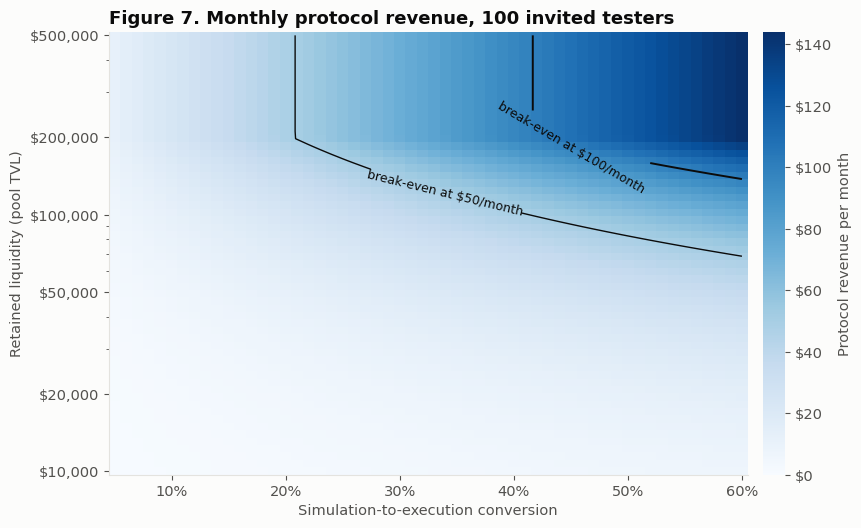

In [26]:
INVITED, CONNECT, ORDERS_PER_USER, DESIRED_ORDER, MAX_IMPACT = 100, 0.60, 8, 1_000.0, 0.01
conversions = np.linspace(0.05, 0.60, 56)
tvls = np.geomspace(10_000, 500_000, 60)

def monthly_volume(invited, conversion, tvl):
    order = min(DESIRED_ORDER, (tvl / 2) * MAX_IMPACT / (1 - MAX_IMPACT))
    return invited * CONNECT * conversion * ORDERS_PER_USER * order

revenue = np.array([[0.0005 * monthly_volume(INVITED, c, v) for c in conversions] for v in tvls])

fig, ax = plt.subplots(figsize=(9, 5.4))
mesh = ax.pcolormesh(conversions, tvls, revenue, cmap="Blues", shading="auto", vmin=0)
cs = ax.contour(conversions, tvls, revenue, levels=COSTS, colors=[INK], linewidths=[1, 1.4, 1.8])
ax.clabel(cs, fmt=lambda v: f"break-even at ${v:.0f}/month", fontsize=9, colors=INK)
ax.set_yscale("log"); ax.yaxis.set_major_formatter(usd); ax.set_yticks([10_000, 20_000, 50_000, 100_000, 200_000, 500_000])
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("Simulation-to-execution conversion"); ax.set_ylabel("Retained liquidity (pool TVL)")
ax.set_title("Figure 7. Monthly protocol revenue, 100 invited testers")
ax.grid(False)
cb = fig.colorbar(mesh, ax=ax, pad=0.02); cb.set_label("Protocol revenue per month"); cb.ax.yaxis.set_major_formatter(usd)
cb.outline.set_visible(False)
fig.tight_layout(); fig.savefig("figures/fig7_revenue_heatmap.png", dpi=200); plt.show()

In [27]:
need_rows = []
for cost in COSTS:
    for tvl in [20_000, 100_000, 500_000]:
        per_user = 0.0005 * monthly_volume(1, 1.0, tvl) / CONNECT     # revenue from one executing user
        executing = cost / per_user
        need_rows.append({"Monthly cost": f"${cost}", "Pool TVL": f"${tvl:,.0f}", "Order size after 1% cap": f"${min(DESIRED_ORDER, tvl / 2 * MAX_IMPACT / (1 - MAX_IMPACT)):,.0f}",
                          "Executing users needed": f"{executing:,.0f}",
                          "Invited at 25% conversion": f"{executing / CONNECT / 0.25:,.0f}",
                          "Invited at 50% conversion": f"{executing / CONNECT / 0.50:,.0f}"})
pd.DataFrame(need_rows)

,Monthly cost,Pool TVL,Order size after 1% cap,Executing users needed,Invited at 25% conversion,Invited at 50% conversion
0,$50,"$20,000",$101,124,825,412
1,$50,"$100,000",$505,25,165,82
2,$50,"$500,000","$1,000",12,83,42
3,$100,"$20,000",$101,248,"1,650",825
4,$100,"$100,000",$505,50,330,165
5,$100,"$500,000","$1,000",25,167,83
6,$200,"$20,000",$101,495,"3,300","1,650"
7,$200,"$100,000",$505,99,660,330
8,$200,"$500,000","$1,000",50,333,167


**Table 12.** Users needed for break-even, by pool depth. Each executing user routes 8 orders a month.

**Findings**
- Break-even volumes are \$100k, \$200k and \$400k a month for \$50, \$100 and \$200 of monthly cost, as stated in the proposal. At 0.05% that is 13, 27 and 53 orders of \$250 a day.
- With 100 invited testers the funnel tops out near \$144 a month (60% conversion, deep liquidity). \$100 a month needs at least 42% conversion with \$200k or more of retained liquidity; \$200 a month is out of reach at this scale.
- The proposal's base case (\$100k TVL, 25% conversion) yields about \$30 a month from 100 testers. Break-even at \$100 needs 50 executing users, which is 330 invited testers at 25% conversion or 165 at 50%.
- Below about \$200k TVL the 1% impact cap binds: at \$20k TVL orders are capped at \$101 and even 60% conversion earns under \$15 a month. Retained liquidity and tester count are the two levers; conversion alone cannot close the gap.
- These are design numbers at 1 USDX = 1 USD. Sepolia fees are test assets, so the report should present break-even as the volume target the design would need, not as expected income.

## 7. Oracle and on-chain reconciliation

**Status on 2026-10-30.** The contracts are on Sepolia (merged to main in commit 89b3ae0). The pool has no liquidity yet and
its settings are not finalized, so no on-chain swap exists to reconcile. Until it does, this section reconciles the model
against the contract's own unit-test vectors (7a) and lists the on-chain checks that follow (7b).

| Contract | Sepolia address | State read by `eth_call` on 2026-10-30 |
|---|---|---|
| AMMPool | `0x629cd6c74032dce6b7342d4fdc5b6be746a5e2f4` | reserves 0 / 0, LP supply 0, dynamic fees enabled, settings not finalized |
| PriceOracle | `0xbba20f70ad1f980e9462879d66d4e3cbd72fe974` | maxAge 5,400 s; ETH/USD 2,234.69, fresh |
| USDX | `0x94d510de252776e02d4f881ae6e41dffd3e6ff67` | 18 decimals, 1,000,000 minted to the deployer |
| WETH | `0x3a6633be400f18be853221774c89130da0e9ccb2` | wrapper, 18 decimals |
| Chainlink ETH/USD | `0x694AA1769357215DE4FAC081bf1f309aDC325306` | 8 decimals, scaled to 18 by PriceOracle |

Pool owner (treasury): `0xe076d9e004ca38abca0453ba2347085f07bf82ea`.

**How the deployed contract treats the oracle** (this differs from the parameter proposal, which said a bad feed blocks swaps):

| Feed condition | Contract behaviour |
|---|---|
| Fresh (≤ 90 min) | both fee signals active |
| Stale (> 90 min) or call reverts | `fresh = false`: TWAP/Chainlink signal switched off, spot/TWAP signal still applies, swaps continue |
| Price ≤ 0, `updatedAt` = 0 or in the future | revert: swaps fail while the condition lasts (only after TWAP warm-up and with dynamic fees on) |
| TWAP warming up (first 30 min after seeding) | fee 0.30%, oracle not read at all |
| Swaps paused by the owner | swaps revert; add and remove liquidity still work |

### 7a. Reconciliation against the contract's unit tests

`packages/hardhat/test/AMMPool.ts` fixes the expected integers for a 1 WETH + 2,500 USDX pool. The same inputs through
`amm_model.py` must give the same integers (all in wei).

In [28]:
E = 10**18
checks = []
def check(name, model, expected):
    checks.append({"Check": name, "Model": str(model), "Contract test": str(expected), "Match": model == expected})

# Swap 0.1 WETH -> USDX (test: "Should swap WETH for USDX and collect fees")
r = amm.swap(E // 10, 1 * E, 2500 * E, amm.BASE_FEE_BPS, amm.PROTOCOL_FEE_BPS)
eff = (E // 10) * 9970 // 10000
check("0.1 WETH in: USDX out", r.amount_out, 2500 * E * eff // (E + eff))
check("0.1 WETH in: protocol fee (WETH)", r.protocol_fee, E * 5 // 100_000)
check("0.1 WETH in: WETH reserve after", r.new_reserve_in, E * 109_995 // 100_000)
check("0.1 WETH in: USDX reserve after", r.new_reserve_out, 2500 * E - 2500 * E * eff // (E + eff))

# Swap 100 USDX -> WETH (test: "Should swap USDX for WETH and collect fees")
r = amm.swap(100 * E, 2500 * E, 1 * E, amm.BASE_FEE_BPS, amm.PROTOCOL_FEE_BPS)
eff = 100 * E * 9970 // 10000
check("100 USDX in: WETH out", r.amount_out, 1 * E * eff // (2500 * E + eff))
check("100 USDX in: protocol fee (USDX)", r.protocol_fee, E * 5 // 100)
check("100 USDX in: USDX reserve after", r.new_reserve_in, E * 259_995 // 100)

# LP shares (tests: initial mint, second LP, burn)
pool7 = amm.Pool(0, 0)
check("first LP: 1 WETH + 2,500 USDX -> shares", pool7.add_liquidity(2500 * E, 1 * E), 50 * E)
check("second LP: 0.5 WETH + 1,250 USDX -> shares", pool7.add_liquidity(1250 * E, E // 2), 25 * E)
check("reserves after second LP (USDX, WETH)", (pool7.reserve_usdx, pool7.reserve_weth), (3750 * E, 3 * E // 2))
pool7 = amm.Pool(0, 0); pool7.add_liquidity(2500 * E, 1 * E)
check("burn 25 of 50 shares -> (USDX, WETH)", pool7.remove_liquidity(25 * E), (1250 * E, E // 2))
check("Sepolia seed: 0.01 WETH + 25 USDX at $2,500 -> shares", amm.Pool(0, 0).add_liquidity(25 * E, E // 100), E // 2)

# TWAP (test: "Should calculate a time-weighted rather than a spot price"): 1,200 s at 2,500, a swap, 600 s at the new spot
r = amm.swap(E // 10, 1 * E, 2500 * E)
spot_after = r.new_reserve_out / r.new_reserve_in  # USDX per WETH after 0.1 WETH in
tw = amm.Twap(1800); tw.record(0, 2500.0); tw.record(1200, spot_after)
check("TWAP after 20 min old + 10 min new price", round(tw.value(1800), 6), round((2500.0 * 1200 + spot_after * 600) / 1800, 6))
check("TWAP once the window holds only the new price", round(tw.value(3000), 6), round(spot_after, 6))
check("TWAP during warm-up", tw.value(1799), None)

# Fee tier (tests: "calculate dynamic fees using oracle prices", "continue swapping ... when Chainlink is stale")
check("pool 2,500 vs Chainlink 2,000 after warm-up -> fee bps", amm.select_fee_bps(2500, 2500, 0.01, reference=2000, reference_trigger=0.01), 50)
check("same, Chainlink stale (fallback) -> fee bps", amm.select_fee_bps(2500, 2500, 0.01, reference=None, reference_trigger=0.01), 30)
check("deviation exactly 100 bps -> fee bps", amm.select_fee_bps(2525, 2500, 0.01), 50)
check("deviation 99 bps -> fee bps", amm.select_fee_bps(2524.75, 2500, 0.01), 30)

rec = pd.DataFrame(checks)
assert rec.Match.all(), rec[~rec.Match]
print(f"{len(rec)} checks, all match")
rec

19 checks, all match


,Check,Model,Contract test,Match
0,0.1 WETH in: USDX out,226652723470037282895,226652723470037282895,True
1,0.1 WETH in: protocol fee (WETH),50000000000000,50000000000000,True
2,0.1 WETH in: WETH reserve after,1099950000000000000,1099950000000000000,True
3,0.1 WETH in: USDX reserve after,2273347276529962717105,2273347276529962717105,True
4,100 USDX in: WETH out,38350578912951494,38350578912951494,True
5,100 USDX in: protocol fee (USDX),50000000000000000,50000000000000000,True
6,100 USDX in: USDX reserve after,2599950000000000000000,2599950000000000000000,True
7,"first LP: 1 WETH + 2,500 USDX -> shares",50000000000000000000,50000000000000000000,True
8,"second LP: 0.5 WETH + 1,250 USDX -> shares",25000000000000000000,25000000000000000000,True
9,"reserves after second LP (USDX, WETH)","(3750000000000000000000, 1500000000000000000)","(3750000000000000000000, 1500000000000000000)",True


**Table 13.** Model versus the contract's unit-test expectations. Every integer matches, so a Sepolia swap that reproduces the
contract's arithmetic will reproduce the model's.

### 7b. On-chain checks still to run

Needed first: the team seeds the pool (0.01 WETH plus 0.01 × Chainlink price in USDX; at 2,234.69 that is 22.35 USDX, about
\$44.7 of TVL) and calls `finalizeSettings()`. Then, for at least one swap transaction:

| Check | Model side | Contract side |
|---|---|---|
| Swap output | `amm.swap` on the pre-trade reserves from `getReserves()` | `amountOut` in `SwapExecuted` |
| Fee tier applied | `select_fee_bps` from `getTwapPrice18()`, `getSpotPrice18()` and the Chainlink answer in that block | `totalFeeBps` in `SwapExecuted` |
| Fee split | `protocol_fee`, reserve change | `protocolFeeAmount` in the event, `protocolFeesUsdx/Weth`, reserve change |
| LP redemption | `Pool.remove_liquidity` pro-rata amounts | `LiquidityRemoved` amounts |
| Gas | the \$6 / \$15 assumptions of Section 3 | `gasUsed` from the receipts at 20 gwei |
| Treasury limit | only accrued protocol fees withdrawable | `withdrawProtocolFees` reverts beyond accrued |

**Operational note for the demo.** Sepolia has no arbitrageurs. Once the pool is seeded its spot price only moves when the team
trades, while Chainlink keeps following the market. As soon as ETH has moved 1% from the seeding price, the TWAP/Chainlink
signal fires and stays on: every swap pays 0.50% until someone trades the pool back toward the market price. The demo should
include that rebalancing trade, or the fee shown on the swap page will look stuck at the high tier.